In [1]:
import os
import glob
from pathlib import Path

import numpy as np
import cv2
import matplotlib.pyplot as plt

In [2]:
# 1. find the folder called "train" anywhere inside /kaggle/input
found = glob.glob("/kaggle/input/**/train", recursive=True)
print(found)

ROOT = Path(found[0]).parent
print("ROOT:", ROOT)
print("inside ROOT:", os.listdir(ROOT))

['/kaggle/input/datasets/balraj98/deepglobe-land-cover-classification-dataset/train']
ROOT: /kaggle/input/datasets/balraj98/deepglobe-land-cover-classification-dataset
inside ROOT: ['class_dict.csv', 'valid', 'metadata.csv', 'test', 'train']


In [3]:
import pandas as pd

sat_paths = sorted(glob.glob(str(ROOT / "train" / "*_sat.jpg")))
print("number of images:", len(sat_paths))
print(sat_paths[:2])

def mask_path_of(sat_path):
    return sat_path.replace("_sat.jpg", "_mask.png")

print(mask_path_of(sat_paths[0]))
print("mask file exists:", os.path.exists(mask_path_of(sat_paths[0])))

print(pd.read_csv(ROOT / "class_dict.csv"))

number of images: 803
['/kaggle/input/datasets/balraj98/deepglobe-land-cover-classification-dataset/train/100694_sat.jpg', '/kaggle/input/datasets/balraj98/deepglobe-land-cover-classification-dataset/train/102122_sat.jpg']
/kaggle/input/datasets/balraj98/deepglobe-land-cover-classification-dataset/train/100694_mask.png
mask file exists: True
               name    r    g    b
0        urban_land    0  255  255
1  agriculture_land  255  255    0
2         rangeland  255    0  255
3       forest_land    0  255    0
4             water    0    0  255
5       barren_land  255  255  255
6           unknown    0    0    0


image: (2448, 2448, 3) uint8 | mask: (2448, 2448, 3) uint8


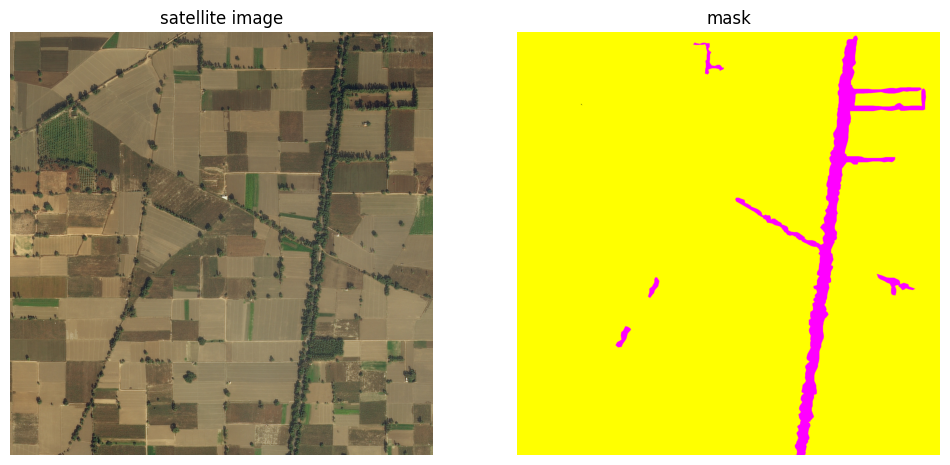

(np.uint8(0), np.uint8(0), np.uint8(0)) 17
(np.uint8(255), np.uint8(0), np.uint8(255)) 245019
(np.uint8(255), np.uint8(255), np.uint8(0)) 5747668


In [4]:
img_bgr  = cv2.imread(sat_paths[0])
mask_bgr = cv2.imread(mask_path_of(sat_paths[0]))
print("image:", img_bgr.shape, img_bgr.dtype, "| mask:", mask_bgr.shape, mask_bgr.dtype)

img  = cv2.cvtColor(img_bgr,  cv2.COLOR_BGR2RGB)
mask = cv2.cvtColor(mask_bgr, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(img);  ax[0].set_title("satellite image"); ax[0].axis("off")
ax[1].imshow(mask); ax[1].set_title("mask");            ax[1].axis("off")
plt.show()

colors, counts = np.unique(mask.reshape(-1, 3), axis=0, return_counts=True)
for c, n in zip(colors, counts):
    print(tuple(c), n)

In [5]:
CLASS_NAMES  = ["urban", "agriculture", "rangeland", "forest", "water", "barren"]
NUM_CLASSES  = 6
IGNORE_INDEX = 255
CLASS_COLORS = np.array([[0,255,255], [255,255,0], [255,0,255],
                         [0,255,0],   [0,0,255],   [255,255,255]], dtype=np.uint8)

LUT = np.full(8, IGNORE_INDEX, dtype=np.uint8)
LUT[3] = 0    # urban
LUT[6] = 1    # agriculture
LUT[5] = 2    # rangeland
LUT[2] = 3    # forest
LUT[1] = 4    # water
LUT[7] = 5    # barren

def rgb_to_class(rgb):
    bits = (rgb >= 128).astype(np.uint8)
    code = bits[..., 0] * 4 + bits[..., 1] * 2 + bits[..., 2]
    return LUT[code]

def class_to_rgb(cls):
    out = np.zeros(cls.shape + (3,), dtype=np.uint8)
    for k in range(NUM_CLASSES):
        out[cls == k] = CLASS_COLORS[k]
    return out

cls = rgb_to_class(mask)
print("shape:", cls.shape, "| dtype:", cls.dtype)
print("class ids present:", np.unique(cls))

shape: (2448, 2448) | dtype: uint8
class ids present: [  1   2 255]


In [6]:
ids, cnts = np.unique(cls, return_counts=True)
for i, c in zip(ids, cnts):
    name = CLASS_NAMES[i] if i < 6 else "unknown"
    print(f"{name:12s} {c:>10,d} pixels  {100*c/cls.size:8.4f}%")

agriculture   5,747,668 pixels   95.9111%
rangeland       245,019 pixels    4.0886%
unknown              17 pixels    0.0003%


In [7]:
for code in range(8):
    r, g, b = (code >> 2) & 1, (code >> 1) & 1, code & 1   # split code back into 3 bits
    print(code, (r*255, g*255, b*255))

0 (0, 0, 0)
1 (0, 0, 255)
2 (0, 255, 0)
3 (0, 255, 255)
4 (255, 0, 0)
5 (255, 0, 255)
6 (255, 255, 0)
7 (255, 255, 255)


In [8]:
import json

ids = [Path(p).name.replace("_sat.jpg", "") for p in sat_paths]   # e.g. "100694"

rng  = np.random.RandomState(42)          # fixed seed -> same shuffle every time
perm = rng.permutation(len(ids))          # a shuffled list of positions 0..802

n_train = int(0.70 * len(ids))            # 562
n_val   = int(0.15 * len(ids))            # 120

split_of = {}
for rank, idx in enumerate(perm):
    if rank < n_train:
        split_of[ids[idx]] = "train"
    elif rank < n_train + n_val:
        split_of[ids[idx]] = "val"
    else:
        split_of[ids[idx]] = "test"

print(pd.Series(split_of).value_counts())

json.dump(split_of, open("/kaggle/working/split.json", "w"))

train    562
test     121
val      120
Name: count, dtype: int64


In [9]:
import time
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm

TILE, GRID = 612, 4                                  # 4 * 612 = 2448

OUT = Path("/kaggle/working/deepglobe_tiles")
(OUT / "images").mkdir(parents=True, exist_ok=True)
(OUT / "masks").mkdir(parents=True, exist_ok=True)

def tile_one(args):
    sat_path, image_id, split = args
    img = cv2.imread(sat_path)                                          # BGR is fine: we save it back as-is
    rgb_mask = cv2.cvtColor(cv2.imread(mask_path_of(sat_path)), cv2.COLOR_BGR2RGB)
    cls = rgb_to_class(rgb_mask)                                        # colours -> class numbers

    rows = []
    for i in range(GRID):                                               # tile row
        for j in range(GRID):                                           # tile column
            y, x = i * TILE, j * TILE
            name = f"{image_id}_{i}{j}"
            cv2.imwrite(str(OUT/"images"/f"{name}.jpg"), img[y:y+TILE, x:x+TILE],
                        [cv2.IMWRITE_JPEG_QUALITY, 95])
            t_cls = cls[y:y+TILE, x:x+TILE]
            cv2.imwrite(str(OUT/"masks"/f"{name}.png"), t_cls)          # lossless

            counts = np.bincount(t_cls.ravel(), minlength=256)          # pixels per class in this tile
            row = {"image_id": image_id, "split": split,
                   "image_path": f"images/{name}.jpg", "mask_path": f"masks/{name}.png"}
            for k, cname in enumerate(CLASS_NAMES):
                row[f"px_{cname}"] = int(counts[k])
            row["px_unknown"] = int(counts[255])
            rows.append(row)
    return rows

jobs = []
for p in sat_paths:
    iid = Path(p).name.replace("_sat.jpg", "")
    jobs.append((p, iid, split_of[iid]))

t0 = time.time()
with ThreadPoolExecutor(max_workers=4) as ex:
    results = list(tqdm(ex.map(tile_one, jobs), total=len(jobs)))

tiles = pd.DataFrame([r for rows in results for r in rows])
tiles.to_csv(OUT / "tiles.csv", index=False)
print(f"{len(tiles)} tiles in {time.time()-t0:.0f}s")
print(tiles.split.value_counts())

100%|██████████| 803/803 [01:18<00:00, 10.25it/s]


12848 tiles in 79s
split
train    8992
test     1936
val      1920
Name: count, dtype: int64


(612, 612, 3) (612, 612) [3]


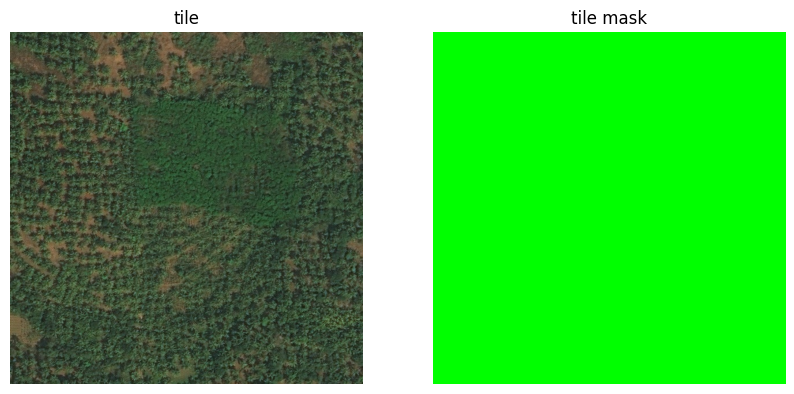

In [10]:
r = tiles[tiles.split == "train"].iloc[100]
t_img  = cv2.cvtColor(cv2.imread(str(OUT / r.image_path)), cv2.COLOR_BGR2RGB)
t_mask = cv2.imread(str(OUT / r.mask_path), cv2.IMREAD_GRAYSCALE)

print(t_img.shape, t_mask.shape, np.unique(t_mask))

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(t_img);                 ax[0].set_title("tile");           ax[0].axis("off")
ax[1].imshow(class_to_rgb(t_mask));  ax[1].set_title("tile mask");      ax[1].axis("off")
plt.show()

In [11]:
cols = [f"px_{c}" for c in CLASS_NAMES]
train_tiles = tiles[tiles.split == "train"]

totals = train_tiles[cols].sum()
share  = 100 * totals / totals.sum()
print(share.round(2))

px_urban          11.04
px_agriculture    56.96
px_rangeland       8.58
px_forest         11.60
px_water           3.71
px_barren          8.11
dtype: float64


In [12]:
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

MEAN = (0.485, 0.456, 0.406)
STD  = (0.229, 0.224, 0.225)
CROP = 512

train_tf = A.Compose([
    A.RandomCrop(height=CROP, width=CROP),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.3),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

val_tf = A.Compose([
    A.CenterCrop(height=CROP, width=CROP),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

In [13]:
from pathlib import Path

class DeepGlobeTiles(Dataset):
    def __init__(self, root, split, transform):
        df = pd.read_csv(Path(root) / "tiles.csv")
        self.df = df[df.split == split].reset_index(drop=True)   # only this split's rows
        self.root = Path(root)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]                                       # row i of the table
        img  = cv2.cvtColor(cv2.imread(str(self.root / r.image_path)), cv2.COLOR_BGR2RGB)
        mask = cv2.imread(str(self.root / r.mask_path), cv2.IMREAD_GRAYSCALE)
        out = self.transform(image=img, mask=mask)
        return out["image"], out["mask"].long()

In [14]:
train_ds = DeepGlobeTiles(OUT, "train", train_tf)
val_ds   = DeepGlobeTiles(OUT, "val",   val_tf)

train_dl = DataLoader(train_ds, batch_size=8, shuffle=True,
                      num_workers=2, pin_memory=True, drop_last=True)
val_dl   = DataLoader(val_ds,   batch_size=8, shuffle=False,
                      num_workers=2, pin_memory=True)

print("train tiles:", len(train_ds), "| batches per epoch:", len(train_dl))
print("val tiles  :", len(val_ds),   "| batches per epoch:", len(val_dl))

train tiles: 8992 | batches per epoch: 1124
val tiles  : 1920 | batches per epoch: 240


In [15]:
x, y = next(iter(train_dl))

print("x:", tuple(x.shape), x.dtype)
print("x value range:", round(x.min().item(), 2), "to", round(x.max().item(), 2))
print("y:", tuple(y.shape), y.dtype)
print("class ids in y:", y.unique().tolist())

x: (8, 3, 512, 512) torch.float32
x value range: -2.12 to 2.64
y: (8, 512, 512) torch.int64
class ids in y: [0, 1, 2, 3, 4, 5]


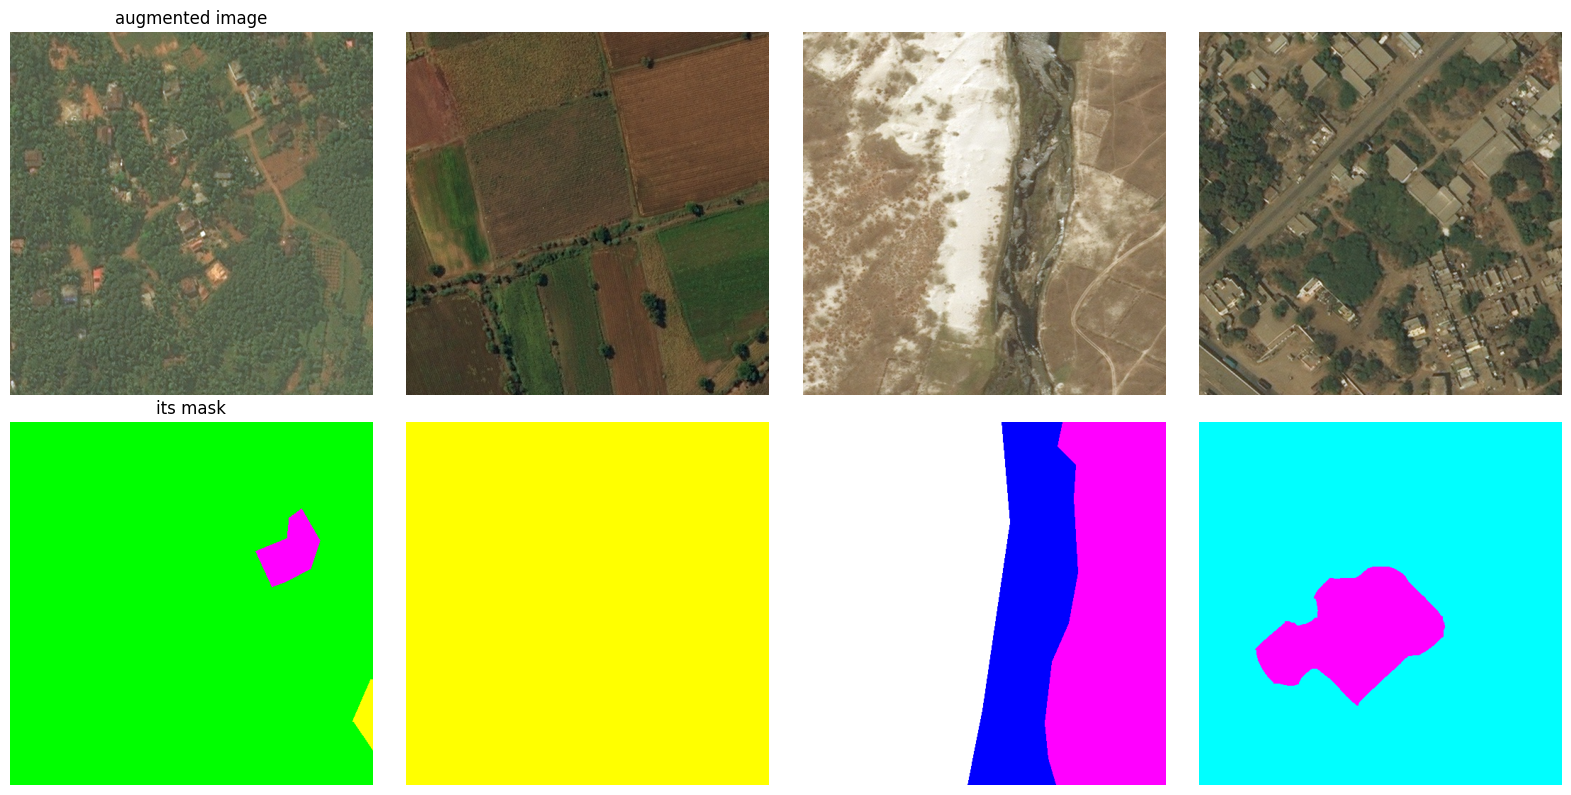

In [16]:
mean = torch.tensor(MEAN).view(3, 1, 1)
std  = torch.tensor(STD).view(3, 1, 1)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for k in range(4):
    img_k = (x[k] * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()   # undo normalization
    axes[0, k].imshow(img_k);                        axes[0, k].axis("off")
    axes[1, k].imshow(class_to_rgb(y[k].numpy()));   axes[1, k].axis("off")
axes[0, 0].set_title("augmented image")
axes[1, 0].set_title("its mask")
plt.tight_layout(); plt.show()

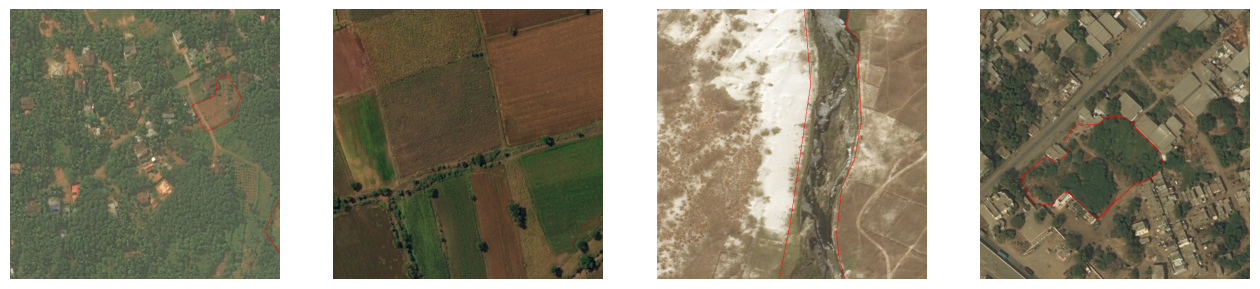

In [17]:
import cv2, numpy as np
mean = torch.tensor(MEAN).view(3,1,1); std = torch.tensor(STD).view(3,1,1)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for k in range(4):
    im = (x[k]*std + mean).clamp(0,1).permute(1,2,0).numpy()
    m  = y[k].numpy().astype(np.uint8)
    edges = cv2.Canny(m, 0, 1) > 0                 # True where the class changes
    im2 = im.copy(); im2[edges] = [1, 0, 0]        # paint those pixels red
    axes[k].imshow(im2); axes[k].axis("off")
plt.show()

px_urban          11.04
px_agriculture    56.96
px_rangeland       8.58
px_forest         11.60
px_water           3.71
px_barren          8.11
dtype: float64

unknown share of all pixels: 0.059%
tiles where one class is >90%: 57.3%


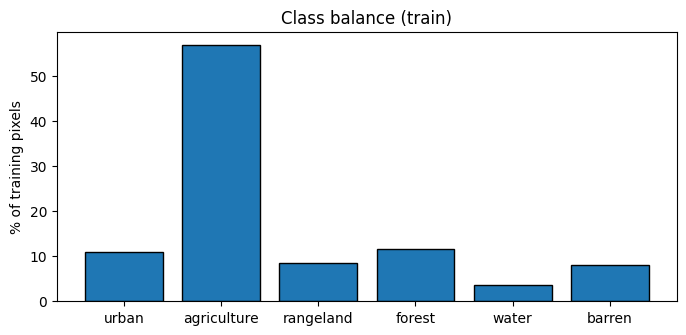

In [18]:
import pandas as pd
import matplotlib.pyplot as plt

OUT = "/kaggle/working/deepglobe_tiles"
tiles = pd.read_csv(f"{OUT}/tiles.csv")

CLASS_NAMES = ["urban", "agriculture", "rangeland", "forest", "water", "barren"]
cols  = [f"px_{c}" for c in CLASS_NAMES]
train = tiles[tiles.split == "train"]          # train only: never design from val/test

# (a) share of each class over all training pixels
totals = train[cols].sum()
share  = 100 * totals / totals.sum()
print(share.round(2))

# (b) how much is "unknown" (ignored)?
unk = train.px_unknown.sum() / (totals.sum() + train.px_unknown.sum())
print(f"\nunknown share of all pixels: {100*unk:.3f}%")

# (c) how one-sided are individual tiles?
tile_share = train[cols].div(train[cols].sum(axis=1), axis=0)
print(f"tiles where one class is >90%: {100*(tile_share.max(axis=1) > 0.9).mean():.1f}%")

# (d) picture
plt.figure(figsize=(8, 3.5))
plt.bar(CLASS_NAMES, share.values, edgecolor="k")
plt.ylabel("% of training pixels"); plt.title("Class balance (train)")
plt.show()

In [19]:
import random
import torch
import torch.nn as nn

OUT = Path("/kaggle/working/deepglobe_tiles")           # Path again (an earlier cell made it a string)
device = "cuda" if torch.cuda.is_available() else "cpu"
IGNORE_INDEX, NUM_CLASSES = 255, 6

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(42)

class SegMetrics:
    def __init__(self, num_classes=NUM_CLASSES, ignore_index=IGNORE_INDEX):
        self.n, self.ignore = num_classes, ignore_index
        self.reset()
    def reset(self):
        self.cm = torch.zeros(self.n, self.n, dtype=torch.long)
    @torch.no_grad()
    def update(self, preds, targets):
        preds, targets = preds.flatten().long(), targets.flatten().long()
        keep = targets != self.ignore
        idx = targets[keep] * self.n + preds[keep]
        self.cm += torch.bincount(idx, minlength=self.n * self.n).reshape(self.n, self.n).cpu()
    def compute(self):
        cm = self.cm.double(); tp = cm.diag()
        fp, fn = cm.sum(0) - tp, cm.sum(1) - tp
        iou = tp / (tp + fp + fn)
        return {"iou_per_class": iou, "mIoU": torch.nanmean(iou).item(),
                "pixel_acc": (tp.sum() / cm.sum()).item()}

print("device:", device, "| train batches:", len(train_dl), "| val batches:", len(val_dl))

device: cuda | train batches: 1124 | val batches: 240


## UNet

In [20]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.block(x)

In [21]:
class Down(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.pool = nn.MaxPool2d(2)              # halve height and width
        self.conv = DoubleConv(in_ch, out_ch)    # then learn features (more channels)
    def forward(self, x):
        return self.conv(self.pool(x))

In [22]:
class Up(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up   = nn.ConvTranspose2d(in_ch, in_ch // 2, kernel_size=2, stride=2)
        self.conv = DoubleConv(in_ch, out_ch)
    def forward(self, x, skip):
        x = self.up(x)                           # double height and width
        x = torch.cat([skip, x], dim=1)          # glue the skip map next to it
        return self.conv(x)

In [23]:
class UNet(nn.Module):
    def __init__(self, in_ch=3, num_classes=6, base=64):
        super().__init__()
        c = base
        self.inc  = DoubleConv(in_ch, c)         # 512x512, 64 ch
        self.d1   = Down(c,     c * 2)           # 256x256, 128 ch
        self.d2   = Down(c * 2, c * 4)           # 128x128, 256 ch
        self.d3   = Down(c * 4, c * 8)           #  64x64,  512 ch
        self.d4   = Down(c * 8, c * 16)          #  32x32, 1024 ch (bottom)
        self.u1   = Up(c * 16, c * 8)
        self.u2   = Up(c * 8,  c * 4)
        self.u3   = Up(c * 4,  c * 2)
        self.u4   = Up(c * 2,  c)
        self.outc = nn.Conv2d(c, num_classes, kernel_size=1)   # 1x1 conv -> class scores

    def forward(self, x):
        x1 = self.inc(x)                         # save these for the skips
        x2 = self.d1(x1)
        x3 = self.d2(x2)
        x4 = self.d3(x3)
        x5 = self.d4(x4)                         # bottom of the "U"
        x  = self.u1(x5, x4)                     # each Up gets the matching saved map
        x  = self.u2(x,  x3)
        x  = self.u3(x,  x2)
        x  = self.u4(x,  x1)
        return self.outc(x)                      # logits (B, 6, H, W)

In [24]:
model = UNet().to(device)
xt = torch.randn(2, 3, 512, 512, device=device)

with torch.no_grad():
    x1 = model.inc(xt); x2 = model.d1(x1); x3 = model.d2(x2)
    x4 = model.d3(x3);  x5 = model.d4(x4)
    print("encoder:", [tuple(t.shape) for t in (x1, x2, x3, x4, x5)])
    out = model(xt)

print("output  :", tuple(out.shape))
print("params  : {:.1f} M".format(sum(p.numel() for p in model.parameters()) / 1e6))

encoder: [(2, 64, 512, 512), (2, 128, 256, 256), (2, 256, 128, 128), (2, 512, 64, 64), (2, 1024, 32, 32)]
output  : (2, 6, 512, 512)
params  : 31.0 M


In [25]:
import torch.nn.functional as F

class DiceLoss(nn.Module):
    def __init__(self, num_classes=6, ignore_index=255, eps=1e-6):
        super().__init__()
        self.n, self.ignore, self.eps = num_classes, ignore_index, eps

    def forward(self, logits, target):
        probs = logits.float().softmax(dim=1)                          # (B,C,H,W), sums to 1 per pixel
        valid = (target != self.ignore)                                # (B,H,W) True where the label is real
        safe  = target.masked_fill(~valid, 0)                          # one_hot can't take 255, so use 0 temporarily
        onehot = F.one_hot(safe, self.n).permute(0, 3, 1, 2).float()   # (B,C,H,W) 1 for the true class
        valid = valid.unsqueeze(1)                                     # (B,1,H,W)
        probs, onehot = probs * valid, onehot * valid                  # zero out ignored pixels

        inter = (probs * onehot).sum(dim=(0, 2, 3))                    # overlap per class -> (C,)
        total = probs.sum(dim=(0, 2, 3)) + onehot.sum(dim=(0, 2, 3))   # predicted area + true area
        dice  = (2 * inter + self.eps) / (total + self.eps)
        present = onehot.sum(dim=(0, 2, 3)) > 0                        # classes that appear in this batch
        return 1 - dice[present].mean()


class CEDiceLoss(nn.Module):
    def __init__(self, class_weights=None):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(weight=class_weights, ignore_index=IGNORE_INDEX)
        self.dice = DiceLoss()

    def forward(self, logits, target):
        logits = logits.float()                                        # do the loss math in full precision
        return self.ce(logits, target) + self.dice(logits, target)

In [26]:
criterion = CEDiceLoss()
xb, yb = next(iter(train_dl))
t = yb[:2].to(device)

# 1) a PERFECT prediction: scores of 20 for the true class, 0 for the rest
safe    = t.masked_fill(t == 255, 0)
perfect = F.one_hot(safe, 6).permute(0, 3, 1, 2).float() * 20
print("perfect  CE:", criterion.ce(perfect, t).item(), "| Dice loss:", criterion.dice(perfect, t).item())

# 2) a CLUELESS prediction: all scores equal, so every class gets probability 1/6
clueless = torch.zeros(2, 6, 512, 512, device=device)
print("clueless CE:", criterion.ce(clueless, t).item(), "| Dice loss:", criterion.dice(clueless, t).item())

perfect  CE: 0.0 | Dice loss: 0.0
clueless CE: 1.7917622327804565 | Dice loss: 0.75


In [27]:
print(t.unique(return_counts=True))

(tensor([1, 3], device='cuda:0'), tensor([262144, 262144], device='cuda:0'))


In [28]:
import torch
from torch.amp import autocast, GradScaler

# 1. Clear GPU memory
del model
torch.cuda.empty_cache()

# 2. Fix seed for reproducibility
seed_everything(42)

# 3. Take 4 tiles from the training loader
xb, yb = next(iter(train_dl))
xb, yb = xb[:4].to(device), yb[:4].to(device)

# 4. Instantiate model, optimizer, scaler, and loss
model = UNet().to(device)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scaler = GradScaler("cuda")
criterion = CEDiceLoss()

# 5. Overfit on these 4 tiles for 40 steps
model.train()
for step in range(1, 41):
    opt.zero_grad(set_to_none=True)
    with autocast("cuda", dtype=torch.float16):
        logits = model(xb)
        loss = criterion(logits, yb)
        
    scaler.scale(loss).backward()
    scaler.step(opt)
    scaler.update()

    if step == 1 or step % 5 == 0:
        print(f"step {step:2d} loss {loss.item():.3f}")

# 6. Evaluate accuracy on the 4 tiles
model.eval()
with torch.no_grad(), autocast("cuda", dtype=torch.float16):
    pred = model(xb).argmax(dim=1)
    m = SegMetrics()
    m.update(pred, yb)
    r = m.compute()
    print("mIoU on these 4 tiles:", round(r["mIoU"], 3), "| pixel acc:", round(r["pixel_acc"], 3))

step  1 loss 2.711
step  5 loss 1.601
step 10 loss 1.257
step 15 loss 1.054
step 20 loss 0.936
step 25 loss 0.761
step 30 loss 0.610
step 35 loss 0.624
step 40 loss 0.476
mIoU on these 4 tiles: 0.714 | pixel acc: 0.911


In [29]:
print(t.unique(return_counts=True))

(tensor([1, 3], device='cuda:0'), tensor([262144, 262144], device='cuda:0'))


In [30]:
import time
import torch
from torch.amp import autocast, GradScaler
from tqdm.auto import tqdm

# --- Configuration ---
NUM_EPOCHS = 15          
MAX_LR = 1e-3
WEIGHT_DECAY = 1e-4
BEST_MODEL_PATH = "best_unet_model.pth"

# 1. Initialize Model, Optimizer, Scaler, and Loss
seed_everything(42)
model = UNet().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=MAX_LR, weight_decay=WEIGHT_DECAY)
scaler = GradScaler("cuda")
criterion = CEDiceLoss()

# 2. Learning Rate Scheduler
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr=MAX_LR,
    steps_per_epoch=len(train_dl),
    epochs=NUM_EPOCHS,
    pct_start=0.2  # Warm up for first 20% of training
)

# 3. Training History Tracking
history = {"train_loss": [], "val_loss": [], "val_mIoU": [], "val_pixel_acc": []}
best_miou = 0.0

print(f"Starting training for {NUM_EPOCHS} epochs on {device}...\n")

for epoch in range(1, NUM_EPOCHS + 1):
    start_time = time.time()
    
    # --- TRAINING PHASE ---
    model.train()
    running_train_loss = 0.0
    
    for x, y in tqdm(train_dl, desc=f"Epoch {epoch:02d}/{NUM_EPOCHS:02d} [Train]", leave=False):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        
        optimizer.zero_grad(set_to_none=True)
        with autocast("cuda", dtype=torch.float16):
            logits = model(x)
            loss = criterion(logits, y)
            
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        
        running_train_loss += loss.item()
        
    epoch_train_loss = running_train_loss / len(train_dl)
    
    # --- VALIDATION PHASE ---
    model.eval()
    running_val_loss = 0.0
    metrics = SegMetrics()
    
    with torch.no_grad():
        for x, y in tqdm(val_dl, desc=f"Epoch {epoch:02d}/{NUM_EPOCHS:02d} [Val]", leave=False):
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            
            with autocast("cuda", dtype=torch.float16):
                logits = model(x)
                loss = criterion(logits, y)
                
            running_val_loss += loss.item()
            metrics.update(logits.argmax(dim=1), y)
            
    epoch_val_loss = running_val_loss / len(val_dl)
    val_results = metrics.compute()
    epoch_val_miou = val_results["mIoU"]
    epoch_val_acc = val_results["pixel_acc"]
    
    elapsed = time.time() - start_time
    
    # Save History
    history["train_loss"].append(epoch_train_loss)
    history["val_loss"].append(epoch_val_loss)
    history["val_mIoU"].append(epoch_val_miou)
    history["val_pixel_acc"].append(epoch_val_acc)
    
    # --- CHECKPOINTING ---
    saved_str = ""
    if epoch_val_miou > best_miou:
        best_miou = epoch_val_miou
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        saved_str = f"--> Saved best model! (mIoU: {best_miou:.4f})"
        
    # Print Epoch Summary
    print(f"Epoch {epoch:02d}/{NUM_EPOCHS:02d} ({elapsed:.0f}s) | "
          f"Train Loss: {epoch_train_loss:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f} | "
          f"Val mIoU: {epoch_val_miou:.4f} | "
          f"Val Acc: {epoch_val_acc:.4f} {saved_str}")

Starting training for 15 epochs on cuda...



Epoch 01/15 [Train]:   0%|          | 0/1124 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [31]:
import time
torch.cuda.empty_cache()
print("GPU:", torch.cuda.get_device_name(0), "| count:", torch.cuda.device_count())

# A) data loading only (skip 5 batches: worker start-up)
it = iter(train_dl)
for _ in range(5): next(it)
t0 = time.time()
for _ in range(40): next(it)
t_data = (time.time() - t0) / 40
print(f"data only: {t_data:.3f} s/batch")

# B) GPU compute only, one fixed batch, throwaway model
bench = UNet().to(device)
opt_b, sc_b = torch.optim.AdamW(bench.parameters(), lr=1e-4), GradScaler("cuda")
xb, yb = next(iter(train_dl)); xb, yb = xb.to(device), yb.to(device)

def step():
    opt_b.zero_grad(set_to_none=True)
    with autocast("cuda", dtype=torch.float16):
        logits = bench(xb)
    loss = criterion(logits, yb)
    sc_b.scale(loss).backward(); sc_b.step(opt_b); sc_b.update()

for _ in range(3): step()                      # warm-up
torch.cuda.synchronize(); t0 = time.time()
for _ in range(15): step()
torch.cuda.synchronize()                       # wait for the GPU to really finish
t_gpu = (time.time() - t0) / 15
print(f"GPU only : {t_gpu:.3f} s/batch")
print(f"epoch estimate: {len(train_dl) * max(t_data, t_gpu) / 60:.1f} min")
del bench, opt_b; torch.cuda.empty_cache()

GPU: Tesla T4 | count: 2
data only: 0.062 s/batch
GPU only : 0.785 s/batch
epoch estimate: 14.7 min


In [32]:
torch.backends.cudnn.benchmark = True          # once, near the top: input size is fixed, so let cuDNN pick the fastest kernels

model = UNet().to(device).to(memory_format=torch.channels_last)

# in both the train and val loops:
x = x.to(device, non_blocking=True, memory_format=torch.channels_last)
y = y.to(device, non_blocking=True)

In [33]:
import time
import torch
from torch.amp import autocast, GradScaler
from tqdm.auto import tqdm
from torch.utils.data import DataLoader

torch.backends.cudnn.benchmark = True

# ---------------- config ----------------
BASE, NUM_EPOCHS, BATCH = 32, 12, 8
MAX_LR, WEIGHT_DECAY = 1e-3, 1e-4
BEST_PATH, LAST_PATH = "best_unet.pth", "last_unet.pth"
CL = torch.channels_last

# ---------------- faster loaders (reuse the datasets from Step 7) ----------------
train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=4,
                      pin_memory=True, drop_last=True, persistent_workers=True)
val_dl   = DataLoader(val_ds, batch_size=BATCH, shuffle=False, num_workers=2,
                      pin_memory=True, persistent_workers=True)

# ---------------- model, optimizer, loss, schedule ----------------
seed_everything(42)
model = UNet(base=BASE).to(device).to(memory_format=CL)
optimizer = torch.optim.AdamW(model.parameters(), lr=MAX_LR, weight_decay=WEIGHT_DECAY)
scaler, criterion = GradScaler("cuda"), CEDiceLoss()
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=MAX_LR, steps_per_epoch=len(train_dl), epochs=NUM_EPOCHS, pct_start=0.2)

print(f"params: {sum(p.numel() for p in model.parameters())/1e6:.1f} M | "
      f"{len(train_dl)} train batches/epoch | {NUM_EPOCHS} epochs")

history = {"train_loss": [], "val_loss": [], "val_mIoU": [], "val_pixel_acc": []}
best_miou, best_iou_per_class = 0.0, None

for epoch in range(1, NUM_EPOCHS + 1):
    t0 = time.time()

    # ----- train -----
    model.train(); run = 0.0
    for x, y in tqdm(train_dl, desc=f"Epoch {epoch:02d} [train]", leave=False):
        x = x.to(device, non_blocking=True, memory_format=CL)
        y = y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with autocast("cuda", dtype=torch.float16):
            logits = model(x)
        loss = criterion(logits, y)                   # 32-bit loss math
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update()
        scheduler.step()
        run += loss.item()
    train_loss = run / len(train_dl)

    # ----- validate -----
    model.eval(); run = 0.0; metrics = SegMetrics()
    with torch.no_grad():
        for x, y in tqdm(val_dl, desc=f"Epoch {epoch:02d} [val]", leave=False):
            x = x.to(device, non_blocking=True, memory_format=CL)
            y = y.to(device, non_blocking=True)
            with autocast("cuda", dtype=torch.float16):
                logits = model(x)
            run += criterion(logits, y).item()
            metrics.update(logits.argmax(dim=1), y)
    val_loss, res = run / len(val_dl), metrics.compute()

    # ----- bookkeeping -----
    history["train_loss"].append(train_loss); history["val_loss"].append(val_loss)
    history["val_mIoU"].append(res["mIoU"]);  history["val_pixel_acc"].append(res["pixel_acc"])

    note = ""
    if res["mIoU"] > best_miou:
        best_miou, best_iou_per_class = res["mIoU"], res["iou_per_class"].clone()
        torch.save({"model": model.state_dict(), "epoch": epoch, "mIoU": best_miou, "base": BASE}, BEST_PATH)
        note = "  <- best, saved"
    torch.save({"model": model.state_dict(), "epoch": epoch, "history": history}, LAST_PATH)

    print(f"Epoch {epoch:02d}/{NUM_EPOCHS} ({time.time()-t0:.0f}s) | train {train_loss:.4f} | "
          f"val {val_loss:.4f} | mIoU {res['mIoU']:.4f} | acc {res['pixel_acc']:.4f}{note}")

params: 7.8 M | 1124 train batches/epoch | 12 epochs


Epoch 01 [train]:   0%|          | 0/1124 [00:00<?, ?it/s]

Epoch 01 [val]:   0%|          | 0/240 [00:00<?, ?it/s]

Epoch 01/12 (313s) | train 2.0133 | val 1.5939 | mIoU 0.2896 | acc 0.6699  <- best, saved


Epoch 02 [train]:   0%|          | 0/1124 [00:00<?, ?it/s]

...

Epoch 11 [val]:   0%|          | 0/240 [00:00<?, ?it/s]

Epoch 11/12 (298s) | train 1.0143 | val 0.9527 | mIoU 0.6010 | acc 0.8299  <- best, saved


Epoch 12 [train]:   0%|          | 0/1124 [00:00<?, ?it/s]

Epoch 12 [val]:   0%|          | 0/240 [00:00<?, ?it/s]

Epoch 12/12 (298s) | train 1.0175 | val 0.9444 | mIoU 0.5972 | acc 0.8309


In [40]:
import json
import torch
from torch.amp import autocast

# 1. Load the model weights properly
checkpoint = torch.load("/kaggle/working/best_unet.pth")
if isinstance(checkpoint, dict) and "model" in checkpoint:
    model.load_state_dict(checkpoint["model"])
else:
    model.load_state_dict(checkpoint)

model.eval()

# 2. Compute metrics on validation set
metrics = SegMetrics()
with torch.no_grad():
    for x, y in val_dl:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with autocast("cuda", dtype=torch.float16):
            logits = model(x)
        metrics.update(logits.argmax(dim=1), y)

val_results = metrics.compute()
best_iou_per_class = val_results["iou_per_class"]
best_miou = val_results["mIoU"]

# 3. Convert tensor to list safely
if hasattr(best_iou_per_class, "cpu"):
    iou_list = best_iou_per_class.cpu().numpy().tolist()
elif hasattr(best_iou_per_class, "tolist"):
    iou_list = best_iou_per_class.tolist()
else:
    iou_list = list(best_iou_per_class)

# 4. Save results to JSON file
results_data = {
    "history": history if "history" in globals() else {},
    "best_mIoU": float(best_miou),
    "best_iou_per_class": iou_list,
    "classes": CLASS_NAMES
}

with open("/kaggle/working/unet_scratch_results.json", "w") as f:
    json.dump(results_data, f, indent=2)

print("Saved unet_scratch_results.json successfully!")

Saved unet_scratch_results.json successfully!


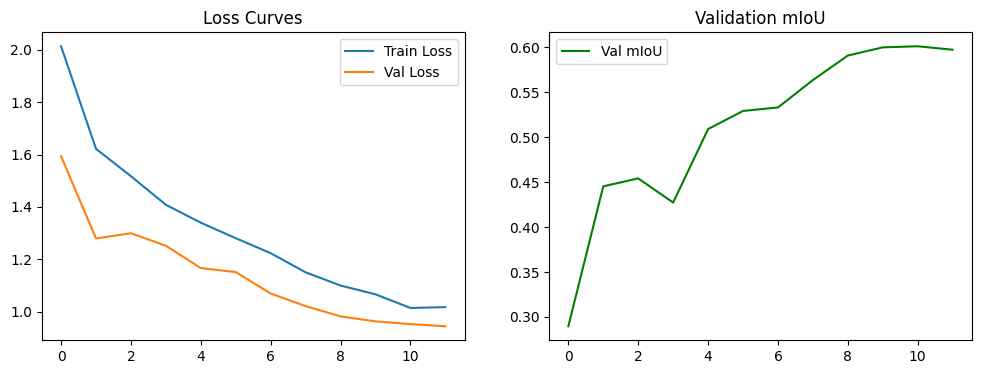

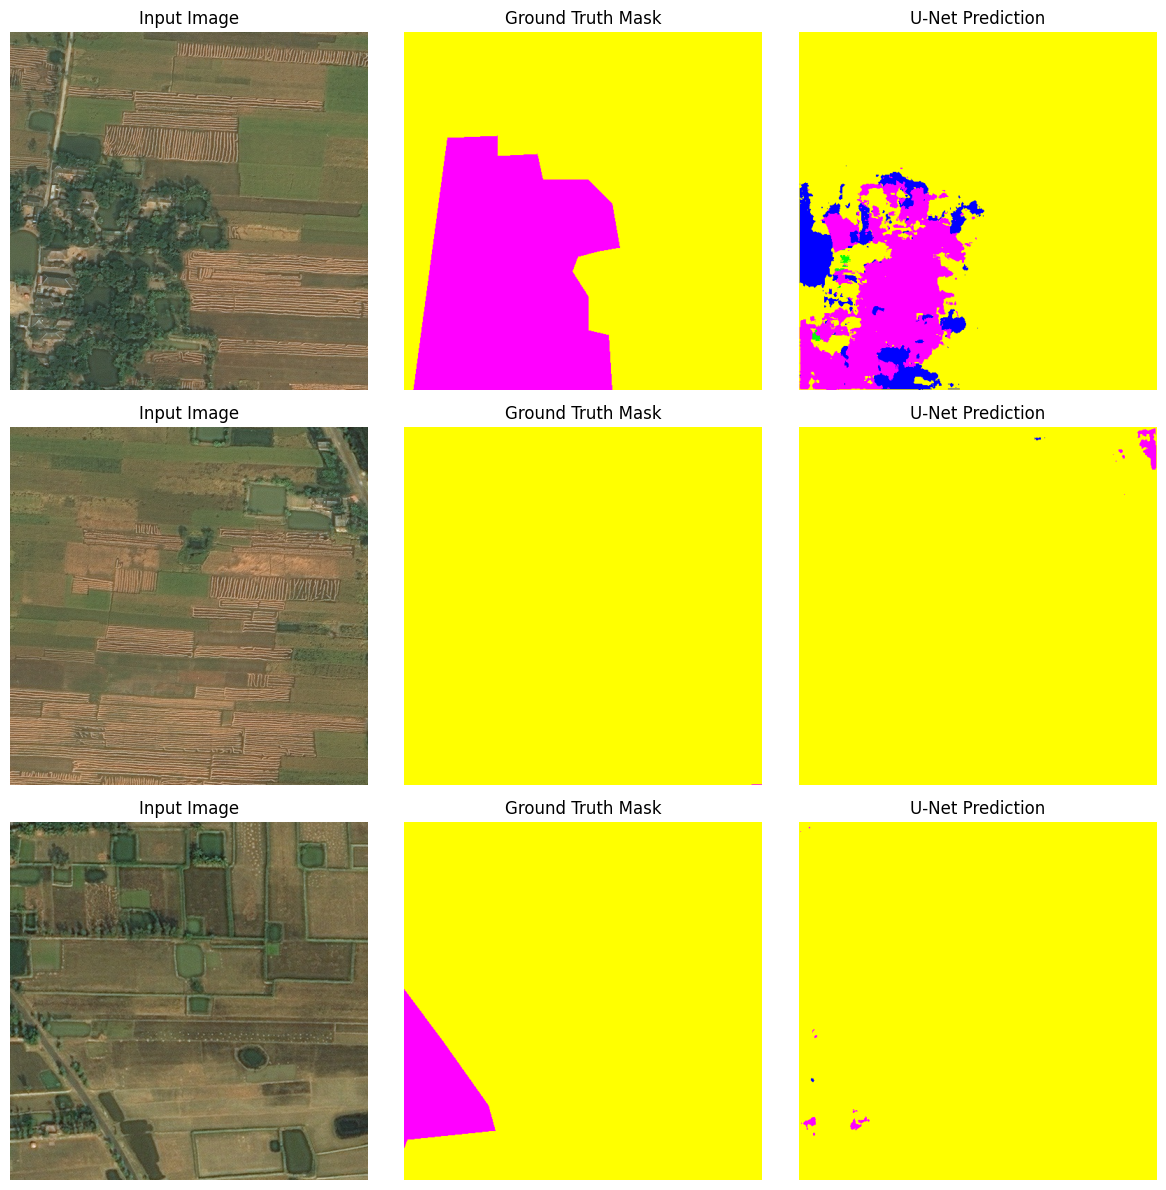

In [41]:
import matplotlib.pyplot as plt
import torch

# 1. Plot Training History
if "history" in globals() and len(history["train_loss"]) > 0:
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    
    ax[0].plot(history["train_loss"], label="Train Loss")
    ax[0].plot(history["val_loss"], label="Val Loss")
    ax[0].set_title("Loss Curves")
    ax[0].legend()
    
    ax[1].plot(history["val_mIoU"], label="Val mIoU", color="green")
    ax[1].set_title("Validation mIoU")
    ax[1].legend()
    plt.show()

# 2. Visualize Predictions on Validation Set
model.eval()
x_vis, y_vis = next(iter(val_dl))
x_vis, y_vis = x_vis[:3].to(device), y_vis[:3]

with torch.no_grad():
    with torch.amp.autocast("cuda", dtype=torch.float16):
        preds = model(x_vis).argmax(dim=1).cpu().numpy()

mean = torch.tensor(MEAN).view(3, 1, 1)
std = torch.tensor(STD).view(3, 1, 1)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))
for i in range(3):
    img = (x_vis[i].cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
    
    axes[i, 0].imshow(img)
    axes[i, 0].set_title("Input Image")
    axes[i, 0].axis("off")
    
    axes[i, 1].imshow(class_to_rgb(y_vis[i].numpy()))
    axes[i, 1].set_title("Ground Truth Mask")
    axes[i, 1].axis("off")
    
    axes[i, 2].imshow(class_to_rgb(preds[i]))
    axes[i, 2].set_title("U-Net Prediction")
    axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

## ResNet34

In [45]:
# install the library that gives us ready made UNet models
!pip install -q segmentation-models-pytorch

import torch
import segmentation_models_pytorch as smp

# use the newer amp tools, these accept "cuda" as the first argument
# the old torch.cuda.amp import was the one causing the error, so it is gone now
from torch.amp import autocast, GradScaler

# free up leftover GPU memory from the scratch UNet training
torch.cuda.empty_cache()

# number of epochs, this must match the value in the training cell
NUM_EPOCHS = 10

# build a UNet with a ResNet34 encoder that already learned from ImageNet
model = smp.Unet(
    encoder_name="resnet34",        # the pretrained backbone
    encoder_weights="imagenet",     # load the ImageNet weights
    in_channels=3,                  # RGB satellite image
    classes=NUM_CLASSES             # 6 land cover classes
).to(device)

print(f"Pretrained U-Net loaded successfully on {device}!")

# optimizer with a smaller learning rate because the encoder is already trained
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

# same loss you used for the scratch UNet, so the comparison stays fair
criterion = CEDiceLoss()

# scaler for half precision training, written in the new style
scaler = GradScaler("cuda")

# cosine schedule that finishes exactly at the last epoch
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)

Pretrained U-Net loaded successfully on cuda!


In [48]:
import gc
import torch
from torch.utils.data import DataLoader

# remove the old loaders so their dead worker processes get cleaned up
del train_dl, val_dl
gc.collect()
torch.cuda.empty_cache()

BATCH = 8

# fresh training loader, built from the same train_ds you already created
# persistent_workers is False here so an interrupt can never leave dead workers behind
train_dl = DataLoader(
    train_ds,
    batch_size=BATCH,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    drop_last=True,
    persistent_workers=False,
)

# fresh validation loader from the same val_ds
val_dl = DataLoader(
    val_ds,
    batch_size=BATCH,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=False,
)

# quick check that the loaders really work before starting the long training
x_test, y_test = next(iter(train_dl))
print("train batch:", tuple(x_test.shape), tuple(y_test.shape))
print("batches per epoch:", len(train_dl), "train |", len(val_dl), "val")

train batch: (8, 3, 512, 512) (8, 512, 512)
batches per epoch: 1124 train | 240 val


In [49]:
import time
from tqdm.auto import tqdm

# speed trick you already used before, tells the GPU to read memory in a faster layout
CL = torch.channels_last
model = model.to(memory_format=CL)
torch.backends.cudnn.benchmark = True

NUM_EPOCHS = 10
BEST_MODEL_PATH = "/kaggle/working/best_pretrained_unet.pth"

best_miou = 0.0
history = {"train_loss": [], "val_loss": [], "val_mIoU": [], "val_pixel_acc": []}

print(f"Starting training for {NUM_EPOCHS} epochs on {device}...\n")

for epoch in range(1, NUM_EPOCHS + 1):
    start_time = time.time()

    # ---------------- training phase ----------------
    model.train()
    running_train_loss = 0.0

    # tqdm draws a live progress bar so you can see every batch moving
    for x, y in tqdm(train_dl, desc=f"Epoch {epoch:02d} [train]", leave=False):
        x = x.to(device, non_blocking=True, memory_format=CL)
        y = y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        # only the model forward pass runs in half precision
        with autocast("cuda", dtype=torch.float16):
            logits = model(x)

        # the loss is calculated in full precision, same as your scratch UNet
        loss = criterion(logits, y)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_train_loss += loss.item()

    # move the cosine schedule forward once per epoch
    scheduler.step()
    epoch_train_loss = running_train_loss / len(train_dl)

    # ---------------- validation phase ----------------
    model.eval()
    running_val_loss = 0.0
    metrics = SegMetrics(num_classes=NUM_CLASSES, ignore_index=IGNORE_INDEX)

    with torch.no_grad():
        for x, y in tqdm(val_dl, desc=f"Epoch {epoch:02d} [val]", leave=False):
            x = x.to(device, non_blocking=True, memory_format=CL)
            y = y.to(device, non_blocking=True)

            with autocast("cuda", dtype=torch.float16):
                logits = model(x)

            running_val_loss += criterion(logits, y).item()
            metrics.update(logits.argmax(dim=1), y)

    epoch_val_loss = running_val_loss / len(val_dl)
    val_results = metrics.compute()
    epoch_val_miou = val_results["mIoU"]
    epoch_val_acc = val_results["pixel_acc"]
    elapsed = time.time() - start_time

    # keep the numbers so we can compare with the scratch UNet later
    history["train_loss"].append(epoch_train_loss)
    history["val_loss"].append(epoch_val_loss)
    history["val_mIoU"].append(epoch_val_miou)
    history["val_pixel_acc"].append(epoch_val_acc)

    # save the weights only when validation mIoU improves
    saved_str = ""
    if epoch_val_miou > best_miou:
        best_miou = epoch_val_miou
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        saved_str = f"<- best, saved (mIoU {best_miou:.4f})"

    print(f"Epoch {epoch:02d}/{NUM_EPOCHS:02d} ({elapsed:.0f}s) | "
          f"train {epoch_train_loss:.4f} | val {epoch_val_loss:.4f} | "
          f"mIoU {epoch_val_miou:.4f} | acc {epoch_val_acc:.4f} {saved_str}")

Starting training for 10 epochs on cuda...



Epoch 01 [train]:   0%|          | 0/1124 [00:00<?, ?it/s]

Epoch 01 [val]:   0%|          | 0/240 [00:00<?, ?it/s]

Epoch 01/10 (247s) | train 1.1510 | val 0.9284 | mIoU 0.6377 | acc 0.8492 <- best, saved (mIoU 0.6377)


Epoch 02 [train]:   0%|          | 0/1124 [00:00<?, ?it/s]

...

Epoch 09 [val]:   0%|          | 0/240 [00:00<?, ?it/s]

Epoch 09/10 (237s) | train 0.7062 | val 0.7102 | mIoU 0.7186 | acc 0.8848 <- best, saved (mIoU 0.7186)


Epoch 10 [train]:   0%|          | 0/1124 [00:00<?, ?it/s]

Epoch 10 [val]:   0%|          | 0/240 [00:00<?, ?it/s]

Epoch 10/10 (237s) | train 0.6913 | val 0.7028 | mIoU 0.7197 | acc 0.8859 <- best, saved (mIoU 0.7197)


In [50]:
import json
import torch
from torch.amp import autocast

# load the best weights that cell 38 saved during training
best_path = "/kaggle/working/best_pretrained_unet.pth"
model.load_state_dict(torch.load(best_path, map_location=device))
model.eval()

# calculate the final metrics on the validation set with the best weights
metrics = SegMetrics(num_classes=NUM_CLASSES, ignore_index=IGNORE_INDEX)
with torch.no_grad():
    for x, y in val_dl:
        x = x.to(device, non_blocking=True, memory_format=torch.channels_last)
        y = y.to(device, non_blocking=True)
        with autocast("cuda", dtype=torch.float16):
            logits = model(x)
        metrics.update(logits.argmax(dim=1), y)

results = metrics.compute()

# turn the per class IoU tensor into a normal python list so json can save it
iou_list = results["iou_per_class"].cpu().numpy().tolist()

# print each class on its own line so it is easy to read
print("Best pretrained UNet on validation set")
for name, value in zip(CLASS_NAMES, iou_list):
    print(f"  {name:12s} IoU: {value:.4f}")
print(f"  mIoU: {results['mIoU']:.4f} | pixel accuracy: {results['pixel_acc']:.4f}")

# save everything to a file, the same way you did for the scratch UNet
results_data = {
    "history": history,
    "best_mIoU": float(results["mIoU"]),
    "best_iou_per_class": iou_list,
    "classes": CLASS_NAMES,
}
with open("/kaggle/working/unet_pretrained_results.json", "w") as f:
    json.dump(results_data, f, indent=2)

print("\nSaved unet_pretrained_results.json successfully!")

Best pretrained UNet on validation set
  urban        IoU: 0.7720
  agriculture  IoU: 0.8840
  rangeland    IoU: 0.4181
  forest       IoU: 0.8128
  water        IoU: 0.7942
  barren       IoU: 0.6371
  mIoU: 0.7197 | pixel accuracy: 0.8859

Saved unet_pretrained_results.json successfully!


In [51]:
import json

# open both result files that you saved
with open("/kaggle/working/unet_scratch_results.json") as f:
    scratch = json.load(f)
with open("/kaggle/working/unet_pretrained_results.json") as f:
    pretrained = json.load(f)

# header line of the comparison table
print(f"{'Class':12s} {'Scratch':>10s} {'Pretrained':>12s} {'Gain':>10s}")

# one line for every land cover class
for i, name in enumerate(scratch["classes"]):
    s = scratch["best_iou_per_class"][i]
    p = pretrained["best_iou_per_class"][i]
    print(f"{name:12s} {s:10.4f} {p:12.4f} {p - s:+10.4f}")

# final line for the overall mIoU
s_m, p_m = scratch["best_mIoU"], pretrained["best_mIoU"]
print(f"{'mIoU':12s} {s_m:10.4f} {p_m:12.4f} {p_m - s_m:+10.4f}")

Class           Scratch   Pretrained       Gain
urban            0.7337       0.7720    +0.0383
agriculture      0.8284       0.8840    +0.0556
rangeland        0.1458       0.4181    +0.2723
forest           0.7378       0.8128    +0.0751
water            0.7083       0.7942    +0.0859
barren           0.4522       0.6371    +0.1849
mIoU             0.6010       0.7197    +0.1187


In [52]:
import os
import json
import time
import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp
from torch.amp import autocast

# stop OpenCV from using extra threads, this avoids data loader freezes
cv2.setNumThreads(0)

# every figure from now on is saved in this folder so you can download them later
FIG_DIR = "/kaggle/working/figures"
os.makedirs(FIG_DIR, exist_ok=True)

# scratch UNet: rebuild it with the same size it was trained with, then load its best weights
scratch_ckpt = torch.load("/kaggle/working/best_unet.pth", map_location=device)
scratch_model = UNet(base=scratch_ckpt["base"]).to(device)
scratch_model.load_state_dict(scratch_ckpt["model"])
scratch_model.eval()

# pretrained UNet: build the same ResNet34 structure, no need to download ImageNet again
pre_model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=NUM_CLASSES,
).to(device)
pre_model.load_state_dict(torch.load("/kaggle/working/best_pretrained_unet.pth", map_location=device))
pre_model.eval()

# free any leftover memory from training
torch.cuda.empty_cache()

print("scratch model parameters   :", round(sum(p.numel() for p in scratch_model.parameters()) / 1e6, 1), "M")
print("pretrained model parameters:", round(sum(p.numel() for p in pre_model.parameters()) / 1e6, 1), "M")

scratch model parameters   : 7.8 M
pretrained model parameters: 24.4 M


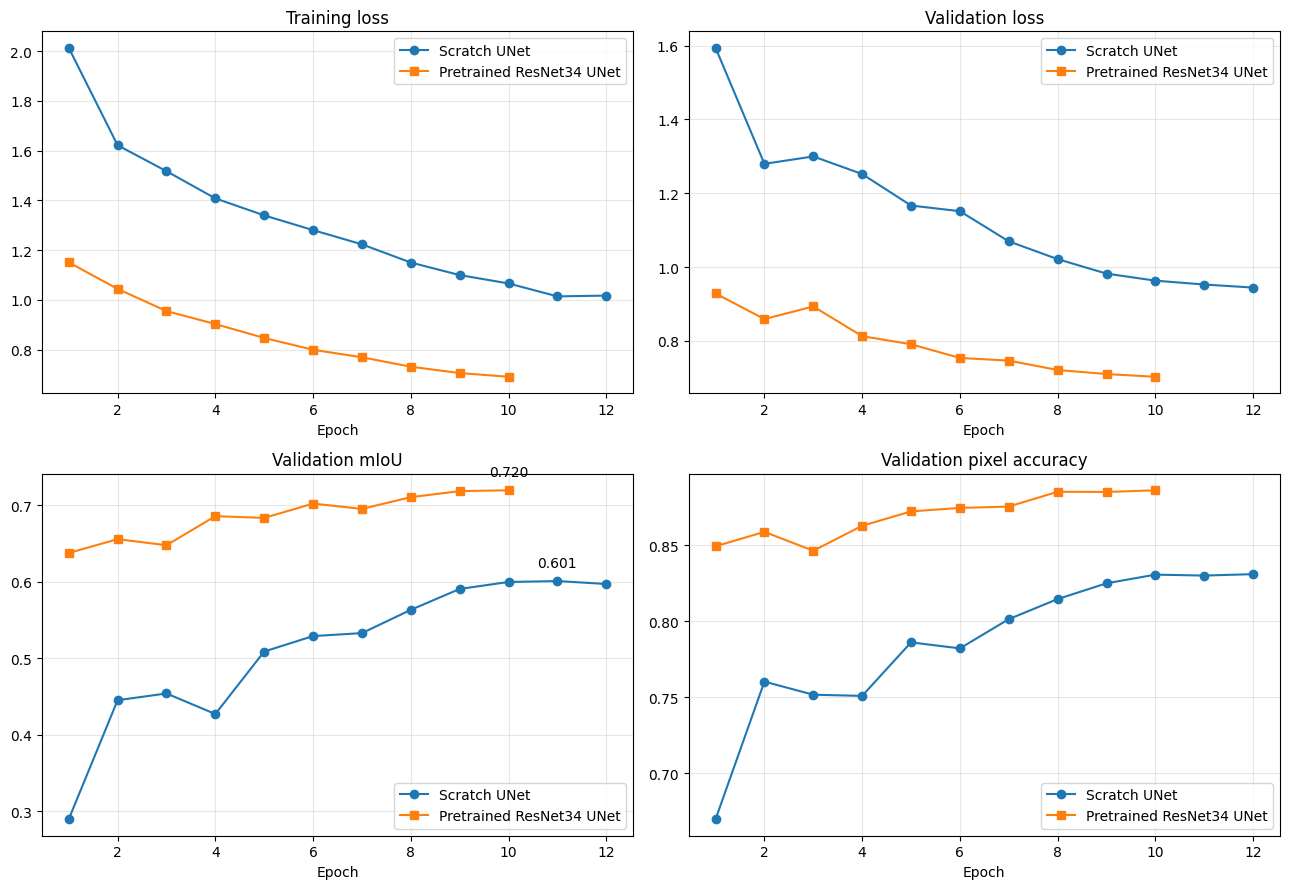

In [53]:
# read the saved training histories of both models
with open("/kaggle/working/unet_scratch_results.json") as f:
    hs = json.load(f)["history"]

# for the pretrained model, use the saved file if Cell A created it, otherwise use the history in memory
try:
    with open("/kaggle/working/unet_pretrained_results.json") as f:
        hp = json.load(f)["history"]
except FileNotFoundError:
    hp = history

# epoch numbers for the x axis, each model can have a different number of epochs
ep_s = np.arange(1, len(hs["val_mIoU"]) + 1)
ep_p = np.arange(1, len(hp["val_mIoU"]) + 1)

fig, ax = plt.subplots(2, 2, figsize=(13, 9))

# each panel is one metric from the history: (axis, key inside history, title)
panels = [
    (ax[0, 0], "train_loss", "Training loss"),
    (ax[0, 1], "val_loss", "Validation loss"),
    (ax[1, 0], "val_mIoU", "Validation mIoU"),
    (ax[1, 1], "val_pixel_acc", "Validation pixel accuracy"),
]
for a, key, title in panels:
    a.plot(ep_s, hs[key], marker="o", label="Scratch UNet")
    a.plot(ep_p, hp[key], marker="s", label="Pretrained ResNet34 UNet")
    a.set_title(title)
    a.set_xlabel("Epoch")
    a.grid(alpha=0.3)
    a.legend()

# write the best mIoU value on the mIoU panel for each model
for hist, eps in [(hs, ep_s), (hp, ep_p)]:
    b = int(np.argmax(hist["val_mIoU"]))
    ax[1, 0].annotate(f"{hist['val_mIoU'][b]:.3f}", (eps[b], hist["val_mIoU"][b]),
                      textcoords="offset points", xytext=(0, 10), ha="center")

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/training_curves.png", dpi=200, bbox_inches="tight")
plt.show()

In [54]:
from torch.utils.data import DataLoader

# the test split was never used for training or for choosing the best epoch
# it uses the same center crop of 512 that validation used
test_ds = DeepGlobeTiles(OUT, "test", val_tf)
test_dl = DataLoader(test_ds, batch_size=8, shuffle=False, num_workers=2, pin_memory=True)
print("test tiles:", len(test_ds))

@torch.no_grad()
def evaluate(model, loader):
    # runs the model on every batch and collects the confusion matrix inside SegMetrics
    model.eval()
    metrics = SegMetrics(num_classes=NUM_CLASSES, ignore_index=IGNORE_INDEX)
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)
        with autocast("cuda", dtype=torch.float16):
            logits = model(x)
        metrics.update(logits.argmax(dim=1), y)
    return metrics

scratch_metrics = evaluate(scratch_model, test_dl)
pre_metrics = evaluate(pre_model, test_dl)

def class_report(metrics):
    # rows of the confusion matrix are true classes, columns are predicted classes
    cm = metrics.cm.double()
    tp = cm.diag()                              # pixels the model got right for each class
    predicted = cm.sum(0)                       # all pixels the model called this class
    actual = cm.sum(1)                          # all pixels that truly belong to this class
    precision = tp / predicted                  # when the model says this class, how often is it right
    recall = tp / actual                        # of the real pixels of this class, how many were found
    f1 = 2 * precision * recall / (precision + recall)
    iou = tp / (predicted + actual - tp)        # overlap divided by combined area
    return pd.DataFrame({"Class": CLASS_NAMES, "IoU": iou.numpy(), "Precision": precision.numpy(),
                         "Recall": recall.numpy(), "F1": f1.numpy()})

scratch_df = class_report(scratch_metrics)
pre_df = class_report(pre_metrics)
scratch_test = scratch_metrics.compute()
pre_test = pre_metrics.compute()

# one comparison table: per class IoU plus the three overall scores
compare = pd.DataFrame({
    "Metric": [f"IoU {c}" for c in CLASS_NAMES] + ["mIoU", "Pixel accuracy", "Mean F1"],
    "Scratch": list(scratch_df["IoU"]) + [scratch_test["mIoU"], scratch_test["pixel_acc"], scratch_df["F1"].mean()],
    "Pretrained": list(pre_df["IoU"]) + [pre_test["mIoU"], pre_test["pixel_acc"], pre_df["F1"].mean()],
})
compare["Gain"] = compare["Pretrained"] - compare["Scratch"]

print("\nTEST SET RESULTS")
print(compare.round(4).to_string(index=False))

print("\nScratch UNet per class report")
print(scratch_df.round(4).to_string(index=False))
print("\nPretrained UNet per class report")
print(pre_df.round(4).to_string(index=False))

# save the tables as CSV files, they open directly in Excel or Power BI
compare.to_csv("/kaggle/working/test_results_comparison.csv", index=False)
scratch_df.to_csv("/kaggle/working/scratch_per_class_test.csv", index=False)
pre_df.to_csv("/kaggle/working/pretrained_per_class_test.csv", index=False)

test tiles: 1936

TEST SET RESULTS
         Metric  Scratch  Pretrained   Gain
      IoU urban   0.7241      0.7669 0.0428
IoU agriculture   0.7933      0.8553 0.0620
  IoU rangeland   0.1789      0.4166 0.2377
     IoU forest   0.6384      0.7355 0.0971
      IoU water   0.5618      0.7154 0.1536
     IoU barren   0.5221      0.6578 0.1357
           mIoU   0.5698      0.6913 0.1215
 Pixel accuracy   0.8050      0.8642 0.0592
        Mean F1   0.7022      0.8089 0.1068

Scratch UNet per class report
      Class    IoU  Precision  Recall     F1
      urban 0.7241     0.8847  0.7995 0.8400
agriculture 0.7933     0.8634  0.9072 0.8847
  rangeland 0.1789     0.3787  0.2532 0.3035
     forest 0.6384     0.7453  0.8164 0.7793
      water 0.5618     0.7468  0.6940 0.7195
     barren 0.5221     0.6848  0.6873 0.6860

Pretrained UNet per class report
      Class    IoU  Precision  Recall     F1
      urban 0.7669     0.9045  0.8345 0.8681
agriculture 0.8553     0.9296  0.9145 0.9220
  rangelan

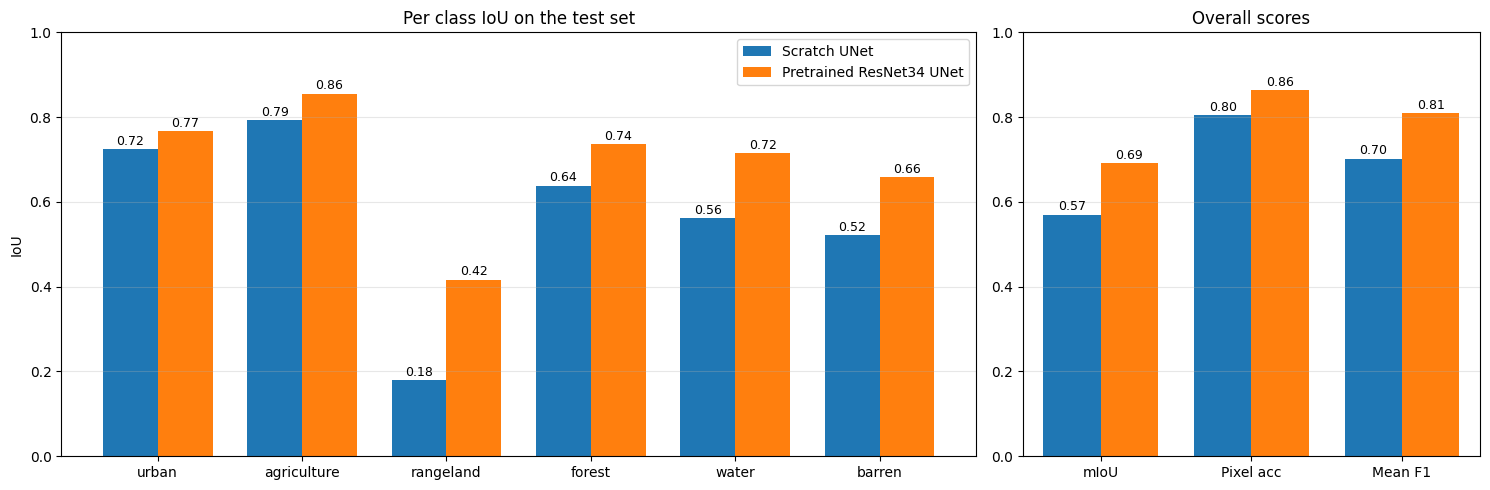

In [55]:
x = np.arange(NUM_CLASSES)
w = 0.38                                         # width of each bar

fig, ax = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2, 1]})

# left panel: IoU of every land cover class for both models
b1 = ax[0].bar(x - w / 2, scratch_df["IoU"], w, label="Scratch UNet")
b2 = ax[0].bar(x + w / 2, pre_df["IoU"], w, label="Pretrained ResNet34 UNet")
ax[0].set_xticks(x)
ax[0].set_xticklabels(CLASS_NAMES)
ax[0].set_ylabel("IoU")
ax[0].set_ylim(0, 1)
ax[0].set_title("Per class IoU on the test set")
ax[0].legend()
ax[0].grid(axis="y", alpha=0.3)
for bars in (b1, b2):
    for r in bars:
        ax[0].text(r.get_x() + r.get_width() / 2, r.get_height() + 0.01, f"{r.get_height():.2f}",
                   ha="center", fontsize=9)

# right panel: the three overall scores
names = ["mIoU", "Pixel acc", "Mean F1"]
s_vals = [scratch_test["mIoU"], scratch_test["pixel_acc"], scratch_df["F1"].mean()]
p_vals = [pre_test["mIoU"], pre_test["pixel_acc"], pre_df["F1"].mean()]
xo = np.arange(3)
c1 = ax[1].bar(xo - w / 2, s_vals, w, label="Scratch UNet")
c2 = ax[1].bar(xo + w / 2, p_vals, w, label="Pretrained ResNet34 UNet")
ax[1].set_xticks(xo)
ax[1].set_xticklabels(names)
ax[1].set_ylim(0, 1)
ax[1].set_title("Overall scores")
ax[1].grid(axis="y", alpha=0.3)
for bars in (c1, c2):
    for r in bars:
        ax[1].text(r.get_x() + r.get_width() / 2, r.get_height() + 0.01, f"{r.get_height():.2f}",
                   ha="center", fontsize=9)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/test_scores.png", dpi=200, bbox_inches="tight")
plt.show()

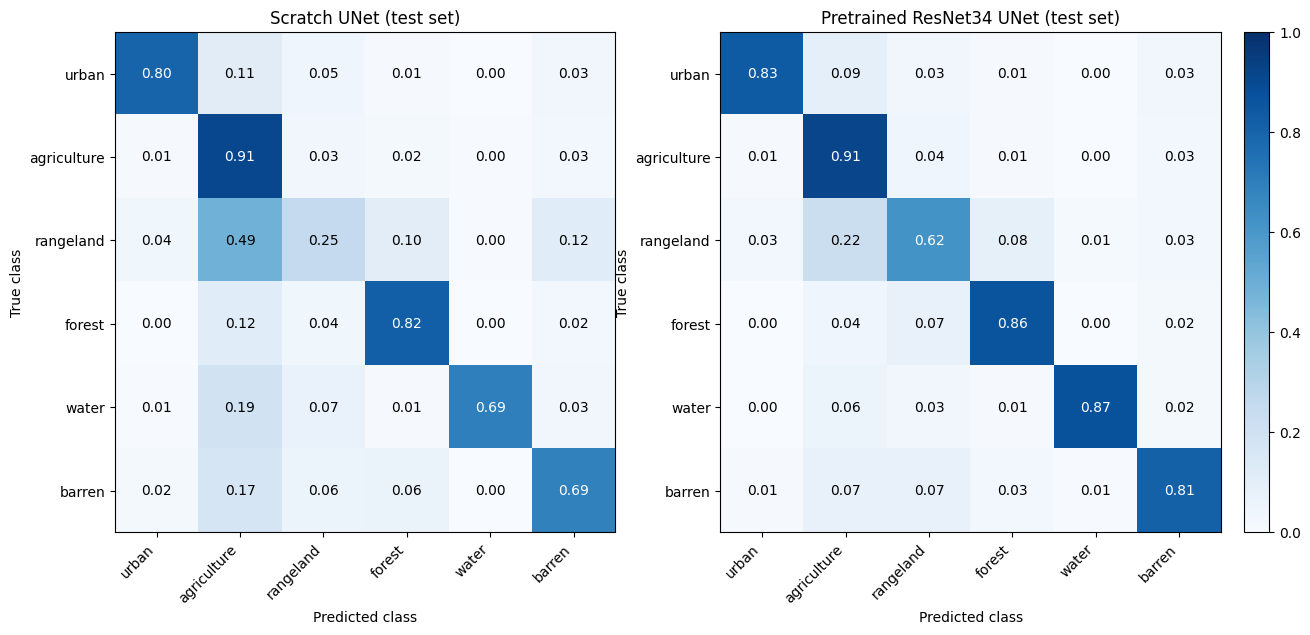

In [56]:
def plot_cm(a, metrics, title):
    # turn counts into shares, so each row adds up to 1 (share of real pixels of that class)
    cm = metrics.cm.numpy().astype(float)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    im = a.imshow(cm_norm, vmin=0, vmax=1, cmap="Blues")
    a.set_xticks(range(NUM_CLASSES))
    a.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
    a.set_yticks(range(NUM_CLASSES))
    a.set_yticklabels(CLASS_NAMES)
    a.set_xlabel("Predicted class")
    a.set_ylabel("True class")
    a.set_title(title)
    # write the share inside every square, white text on dark squares so it stays readable
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            a.text(j, i, f"{cm_norm[i, j]:.2f}", ha="center", va="center",
                   color="white" if cm_norm[i, j] > 0.5 else "black")
    return im

fig, ax = plt.subplots(1, 2, figsize=(15, 6.5))
plot_cm(ax[0], scratch_metrics, "Scratch UNet (test set)")
im = plot_cm(ax[1], pre_metrics, "Pretrained ResNet34 UNet (test set)")
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
plt.savefig(f"{FIG_DIR}/confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

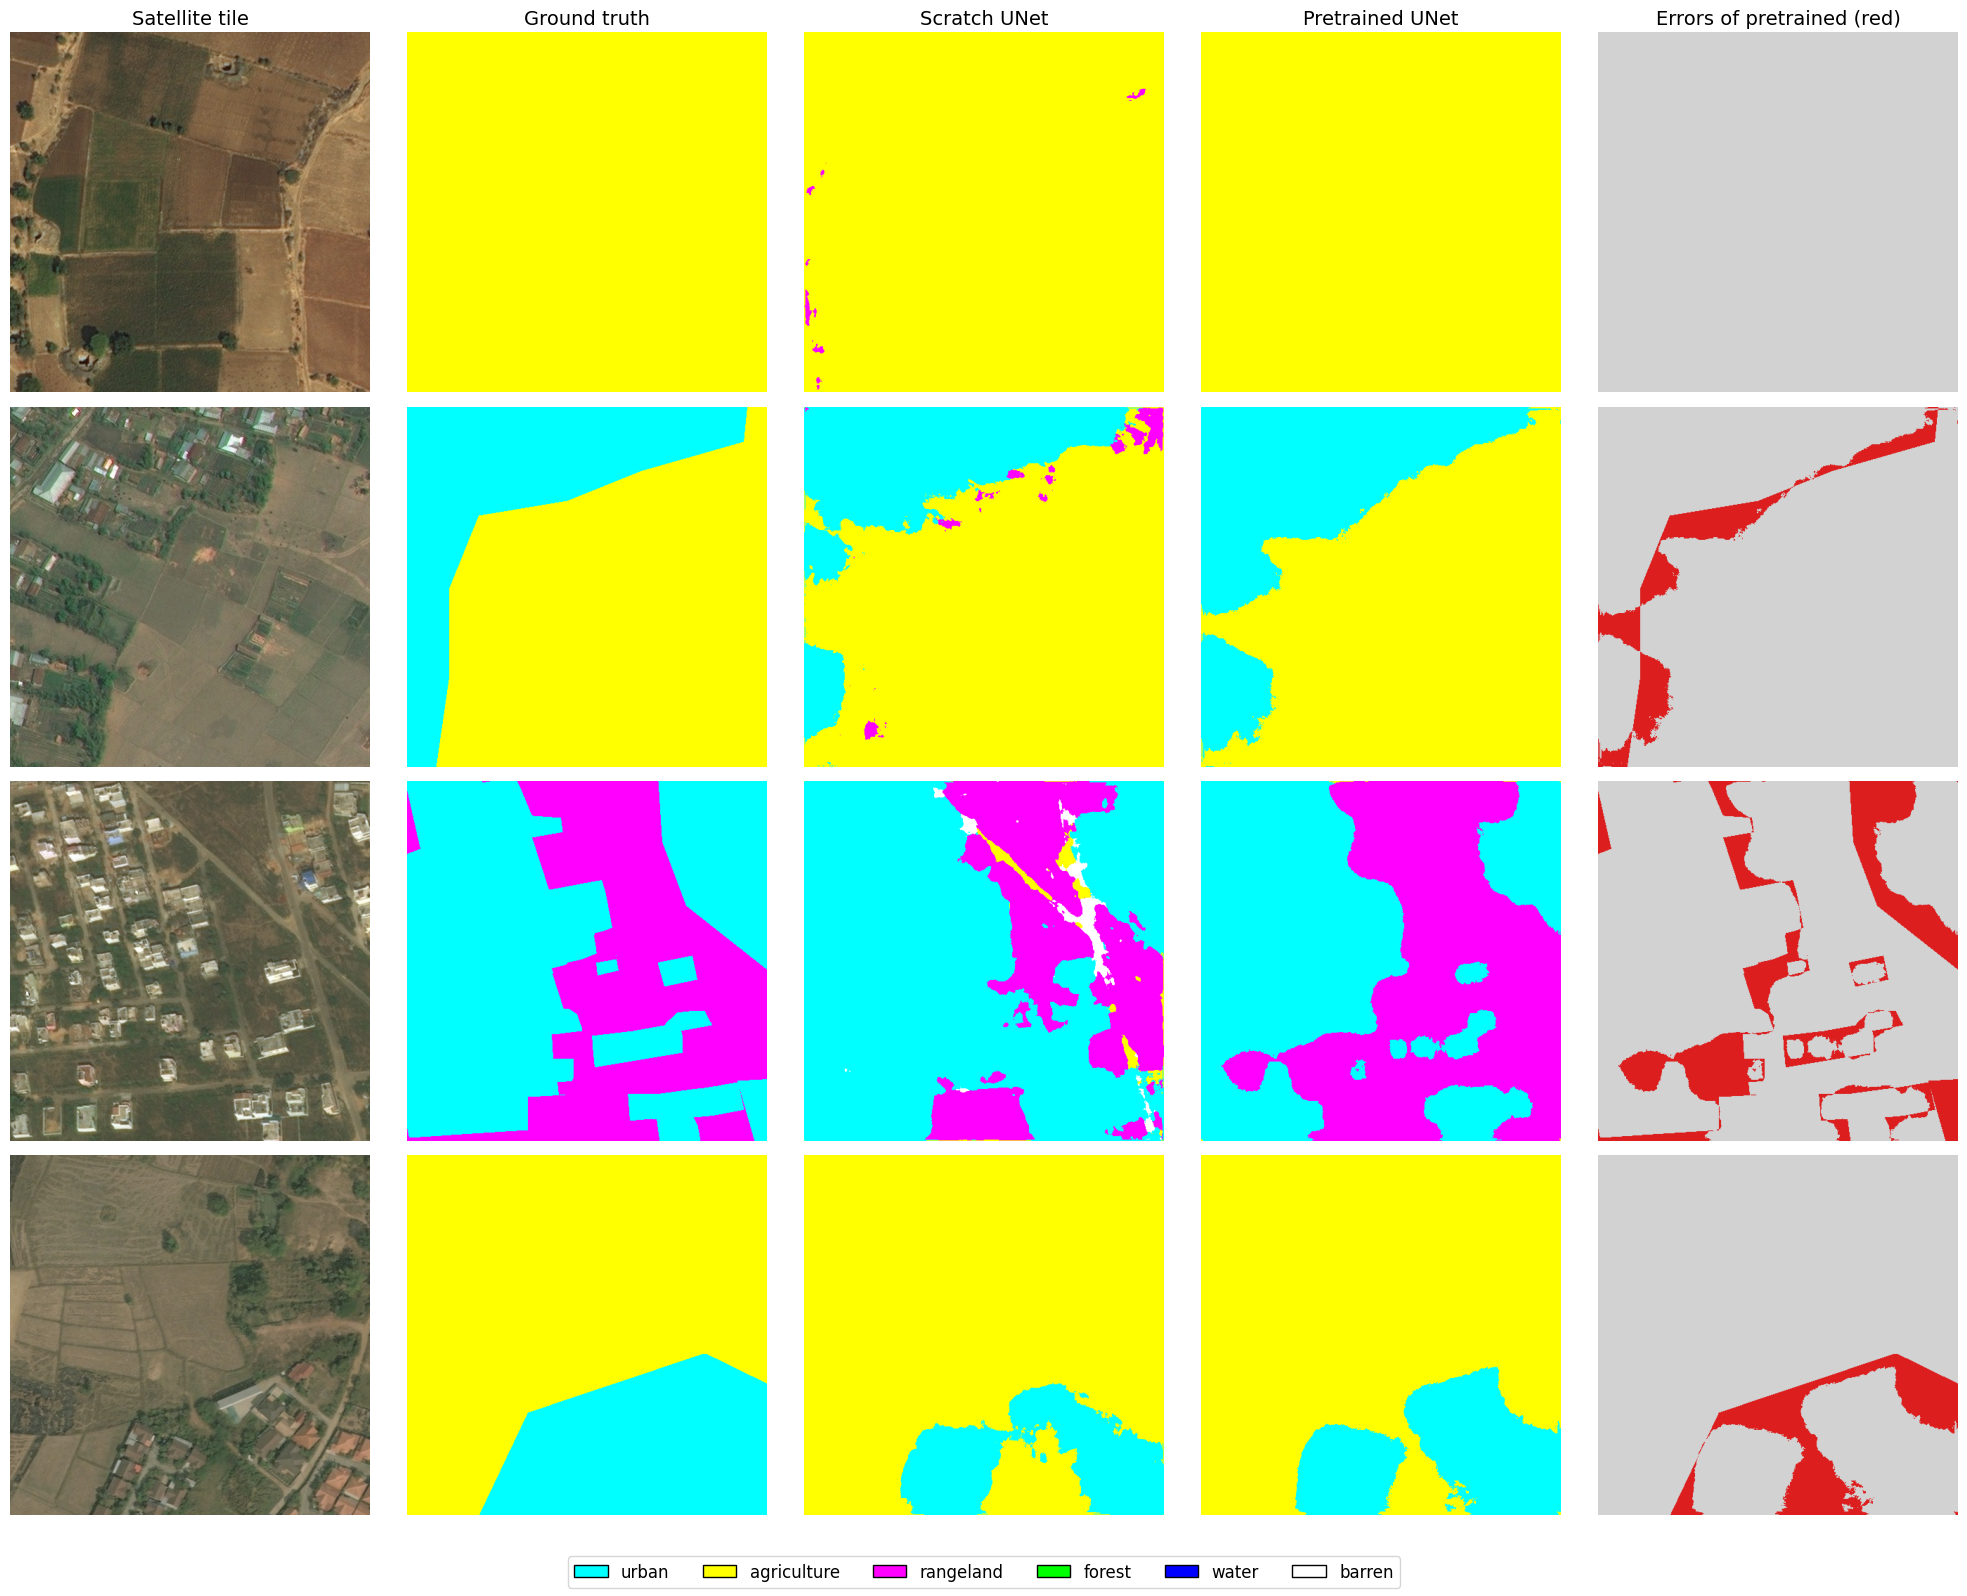

In [57]:
from matplotlib.patches import Patch

# pick 4 test tiles, the seed keeps the same tiles every time you run the cell
rng = np.random.RandomState(7)
pick = rng.choice(len(test_ds), size=4, replace=False)

# load those tiles through the test dataset, so they get the same preprocessing as evaluation
items = [test_ds[int(i)] for i in pick]
xb = torch.stack([it[0] for it in items]).to(device)
yb = torch.stack([it[1] for it in items]).numpy()

with torch.no_grad(), autocast("cuda", dtype=torch.float16):
    p_scratch = scratch_model(xb).argmax(dim=1).cpu().numpy()
    p_pre = pre_model(xb).argmax(dim=1).cpu().numpy()

def error_map(pred, gt):
    # light grey means correct, red means the model was wrong
    out = np.full(pred.shape + (3,), 210, dtype=np.uint8)
    wrong = (pred != gt) & (gt != IGNORE_INDEX)
    out[wrong] = [220, 30, 30]
    return out

# undo the normalization so the satellite tile looks natural again
mean_t = torch.tensor(MEAN).view(3, 1, 1)
std_t = torch.tensor(STD).view(3, 1, 1)

titles = ["Satellite tile", "Ground truth", "Scratch UNet", "Pretrained UNet", "Errors of pretrained (red)"]
fig, axes = plt.subplots(4, 5, figsize=(20, 16))
for r in range(4):
    img = (xb[r].cpu() * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()
    cols = [img, class_to_rgb(yb[r]), class_to_rgb(p_scratch[r]), class_to_rgb(p_pre[r]),
            error_map(p_pre[r], yb[r])]
    for c in range(5):
        axes[r, c].imshow(cols[c])
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(titles[c], fontsize=14)

# colour legend for the land cover classes
handles = [Patch(facecolor=CLASS_COLORS[k] / 255, edgecolor="k", label=CLASS_NAMES[k]) for k in range(NUM_CLASSES)]
fig.legend(handles=handles, loc="lower center", ncol=NUM_CLASSES, fontsize=12)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(f"{FIG_DIR}/prediction_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

image id: 102122
scratch pixel accuracy   : 0.9696
pretrained pixel accuracy: 0.9776


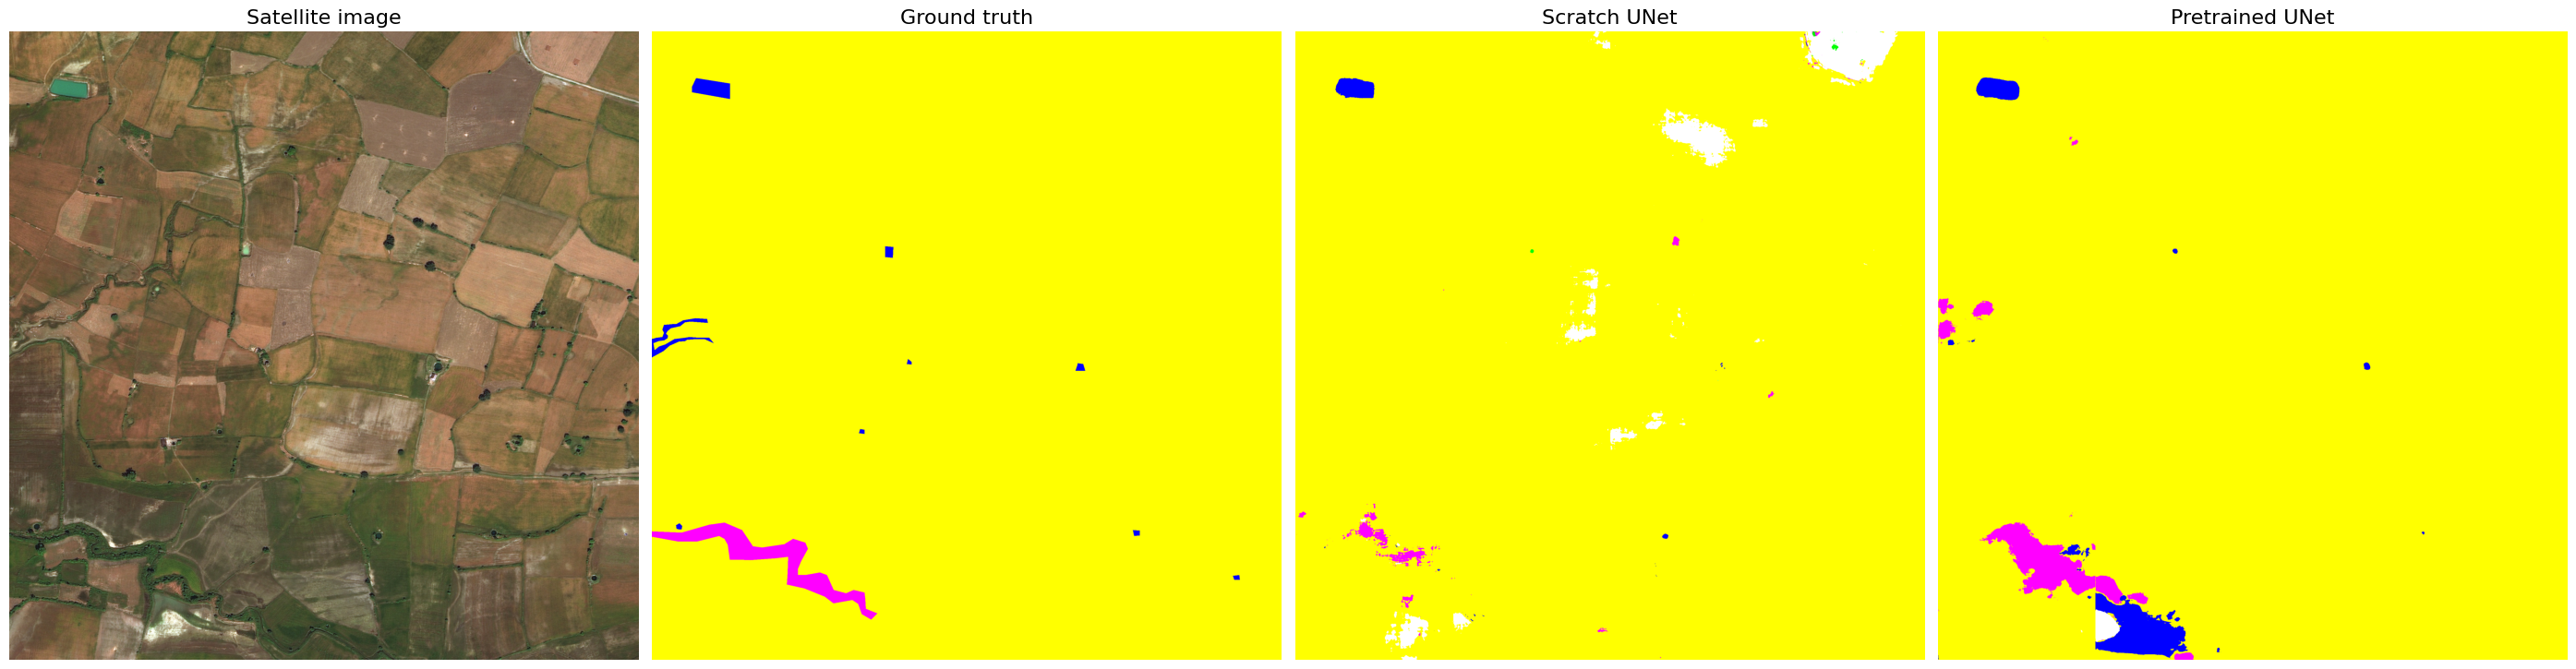

In [58]:
# split file remembers which images belong to the test set
with open("/kaggle/working/split.json") as f:
    split_of = json.load(f)
test_ids = sorted([k for k, v in split_of.items() if v == "test"])

# choose the first test image, change the number to see a different one
image_id = test_ids[0]
sat_path = str(ROOT / "train" / f"{image_id}_sat.jpg")

# load the satellite image and its true class map
img_rgb = cv2.cvtColor(cv2.imread(sat_path), cv2.COLOR_BGR2RGB)
gt_rgb = cv2.cvtColor(cv2.imread(mask_path_of(sat_path)), cv2.COLOR_BGR2RGB)
gt_cls = rgb_to_class(gt_rgb)

MEAN_A = np.array(MEAN, dtype=np.float32)
STD_A = np.array(STD, dtype=np.float32)

@torch.no_grad()
def predict_big_image(model, img):
    # cut the big image into the same 16 tiles of 612 used during tiling
    out = np.zeros(img.shape[:2], dtype=np.uint8)
    for i in range(GRID):
        for j in range(GRID):
            y0, x0 = i * TILE, j * TILE
            tile = img[y0:y0 + TILE, x0:x0 + TILE]
            # same normalization as training
            x = (tile.astype(np.float32) / 255.0 - MEAN_A) / STD_A
            x = torch.from_numpy(x).permute(2, 0, 1).unsqueeze(0).to(device)
            # 612 cannot be divided by 32, so pad to 640, predict, then cut the padding off
            pad = 640 - TILE
            x = F.pad(x, (0, pad, 0, pad), mode="reflect")
            with autocast("cuda", dtype=torch.float16):
                logits = model(x)
            pred = logits[:, :, :TILE, :TILE].argmax(dim=1)[0].cpu().numpy().astype(np.uint8)
            out[y0:y0 + TILE, x0:x0 + TILE] = pred
    return out

big_scratch = predict_big_image(scratch_model, img_rgb)
big_pre = predict_big_image(pre_model, img_rgb)

# pixel accuracy on this one image, ignoring unknown pixels
valid = gt_cls != IGNORE_INDEX
print("image id:", image_id)
print("scratch pixel accuracy   :", round(float((big_scratch == gt_cls)[valid].mean()), 4))
print("pretrained pixel accuracy:", round(float((big_pre == gt_cls)[valid].mean()), 4))

fig, ax = plt.subplots(1, 4, figsize=(28, 7.5))
for a, im, t in zip(ax, [img_rgb, class_to_rgb(gt_cls), class_to_rgb(big_scratch), class_to_rgb(big_pre)],
                    ["Satellite image", "Ground truth", "Scratch UNet", "Pretrained UNet"]):
    a.imshow(im)
    a.set_title(t, fontsize=16)
    a.axis("off")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/full_image_prediction.png", dpi=120, bbox_inches="tight")
plt.show()

In [59]:
def model_facts(model, path):
    # parameters in millions, saved file size in MB, and time for one batch of 8 tiles
    params = sum(p.numel() for p in model.parameters()) / 1e6
    size_mb = os.path.getsize(path) / 1e6
    x = torch.randn(8, 3, 512, 512, device=device)
    with torch.no_grad(), autocast("cuda", dtype=torch.float16):
        for _ in range(3):
            model(x)                              # warm up so the timing is fair
        torch.cuda.synchronize()
        t0 = time.time()
        for _ in range(10):
            model(x)
        torch.cuda.synchronize()
    ms = (time.time() - t0) / 10 * 1000
    return params, size_mb, ms

rows = []
for name, m, p in [("Scratch UNet", scratch_model, "/kaggle/working/best_unet.pth"),
                   ("Pretrained ResNet34 UNet", pre_model, "/kaggle/working/best_pretrained_unet.pth")]:
    params, size_mb, ms = model_facts(m, p)
    rows.append({"Model": name, "Parameters (M)": round(params, 1),
                 "Weights file (MB)": round(size_mb, 1), "Inference ms per batch of 8": round(ms, 1)})

facts = pd.DataFrame(rows)
print(facts.to_string(index=False))
facts.to_csv("/kaggle/working/model_facts.csv", index=False)

                   Model  Parameters (M)  Weights file (MB)  Inference ms per batch of 8
            Scratch UNet             7.8               31.1                         94.7
Pretrained ResNet34 UNet            24.4               97.9                         67.0


In [60]:
import os
import zipfile
from IPython.display import FileLink, display

WORK = "/kaggle/working"
os.chdir(WORK)                                    # the download link works from this folder

# every result file we want inside the package, missing ones are simply skipped
files_to_pack = [
    "best_unet.pth",
    "best_pretrained_unet.pth",
    "unet_scratch_results.json",
    "unet_pretrained_results.json",
    "test_results_comparison.csv",
    "scratch_per_class_test.csv",
    "pretrained_per_class_test.csv",
    "model_facts.csv",
    "split.json",
]

zip_name = "land_cover_unet_results.zip"
with zipfile.ZipFile(os.path.join(WORK, zip_name), "w", zipfile.ZIP_DEFLATED) as z:
    for name in files_to_pack:
        path = os.path.join(WORK, name)
        if os.path.exists(path):
            z.write(path, arcname=name)
        else:
            print("skipped, not found:", name)
    # add all the figures inside a figures folder
    FIG_DIR = os.path.join(WORK, "figures")
    if os.path.isdir(FIG_DIR):
        for name in sorted(os.listdir(FIG_DIR)):
            z.write(os.path.join(FIG_DIR, name), arcname=f"figures/{name}")

print("zip size:", round(os.path.getsize(os.path.join(WORK, zip_name)) / 1e6, 1), "MB")
display(FileLink(zip_name))

zip size: 123.7 MB


/kaggle/working/land_cover_unet_results.zip